# LightGBM L2 검증 결과

L1=0 · L2=1.0 · 검증 2022~2025년 · USD·FOB

현재 수정치 기반 과거 검증이며, 2027년 예측은 아닙니다.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

RUN_ID = "lightgbm_v001_l2_lambda1_20261104_01"
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "artifacts" / RUN_ID).is_dir()), None)
if ROOT is None: raise FileNotFoundError("D:/five-stack 또는 notebooks에서 실행해 주세요.")
RUN = ROOT / "artifacts" / RUN_ID
OLD = ROOT / "artifacts/lightgbm_v001_initial_20261104_01"
FIGURES = RUN / "figures"
FIGURES.mkdir(exist_ok=True)
font_path = Path("C:/Windows/Fonts/malgun.ttf")
if font_path.exists():
    font_manager.fontManager.addfont(str(font_path))
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(font_path)).get_name()
plt.rcParams.update({"axes.unicode_minus":False, "axes.spines.top":False, "axes.spines.right":False,
                     "figure.dpi":110, "savefig.dpi":160, "axes.labelsize":11, "font.size":10})
meta = json.loads((RUN / "run_metadata.json").read_text(encoding="utf-8"))
new = pd.read_parquet(RUN / "validation_predictions.parquet")
old = pd.read_parquet(OLD / "validation_predictions.parquet")
metrics = pd.read_csv(RUN / "metrics.csv", dtype={"group_value":"string"})
old_metrics = pd.read_csv(OLD / "metrics.csv", dtype={"group_value":"string"})
KEY = ["country_code", "hs_code", "origin_quarter", "target_quarter", "variant"]
ACTUAL, PRED = "target_export_value_usd", "predicted_export_value_usd"
countries = yaml.safe_load((ROOT / "configs/countries.yaml").read_text(encoding="utf-8"))["countries"]
country_names = {r["iso3"]:r["name_ko"] for r in countries}
labels = {"with_macro":"거시 포함", "without_macro":"거시 제외"}
for variant in labels:
    a=new[new.variant.eq(variant)].sort_values(KEY)
    b=old[old.variant.eq(variant)].sort_values(KEY)
    assert a[KEY].reset_index(drop=True).equals(b[KEY].reset_index(drop=True))
    np.testing.assert_array_equal(a[ACTUAL].to_numpy(), b[ACTUAL].to_numpy())

## 1. 규제 없음·L1·L2 성능

h=2~5, 동일 9,164행. 오차는 낮을수록 좋습니다.

In [2]:
tables=[]
L1=ROOT/"artifacts/lightgbm_v001_l1_alpha1_20261104_01"
for name,frame in [("규제 없음",old_metrics),("L1=1.0",pd.read_csv(L1/"metrics.csv")),("L2=1.0",metrics)]:
    part=frame.loc[frame.model_id.eq("lightgbm") & frame.scope.eq("h2_5") & frame.group_by.eq("overall"),
                   ["variant","n","wape","mae","rmse","smape"]].copy()
    part.insert(0,"실험",name)
    tables.append(part)
comparison=pd.concat(tables,ignore_index=True)
comparison["구성"]=comparison.variant.map(labels)
display(comparison[["실험","구성","n","wape","mae","rmse","smape"]].rename(columns={"n":"평가 건수","wape":"WAPE (%)","mae":"MAE (USD)","rmse":"RMSE (USD)","smape":"sMAPE (%)"}))
comparison.to_csv(RUN/"regularization_comparison.csv",index=False,encoding="utf-8-sig")


,실험,구성,평가 건수,WAPE (%),MAE (USD),RMSE (USD),sMAPE (%)
0,규제 없음,거시 포함,9164,27.447588,2.958973e+06,1.751461e+07,69.799015
1,규제 없음,거시 제외,9164,26.884774,2.898299e+06,1.727267e+07,68.879224
2,L1=1.0,거시 포함,9164,27.447588,2.958973e+06,1.751461e+07,69.799015
3,L1=1.0,거시 제외,9164,26.884774,2.898299e+06,1.727267e+07,68.879224
4,L2=1.0,거시 포함,9164,26.732187,2.881849e+06,1.713850e+07,69.725771
5,L2=1.0,거시 제외,9164,26.889263,2.898783e+06,1.734707e+07,68.694456


## 2. 실측값·예측값

대각선에 가까울수록 일치합니다. 단위: 백만 USD.

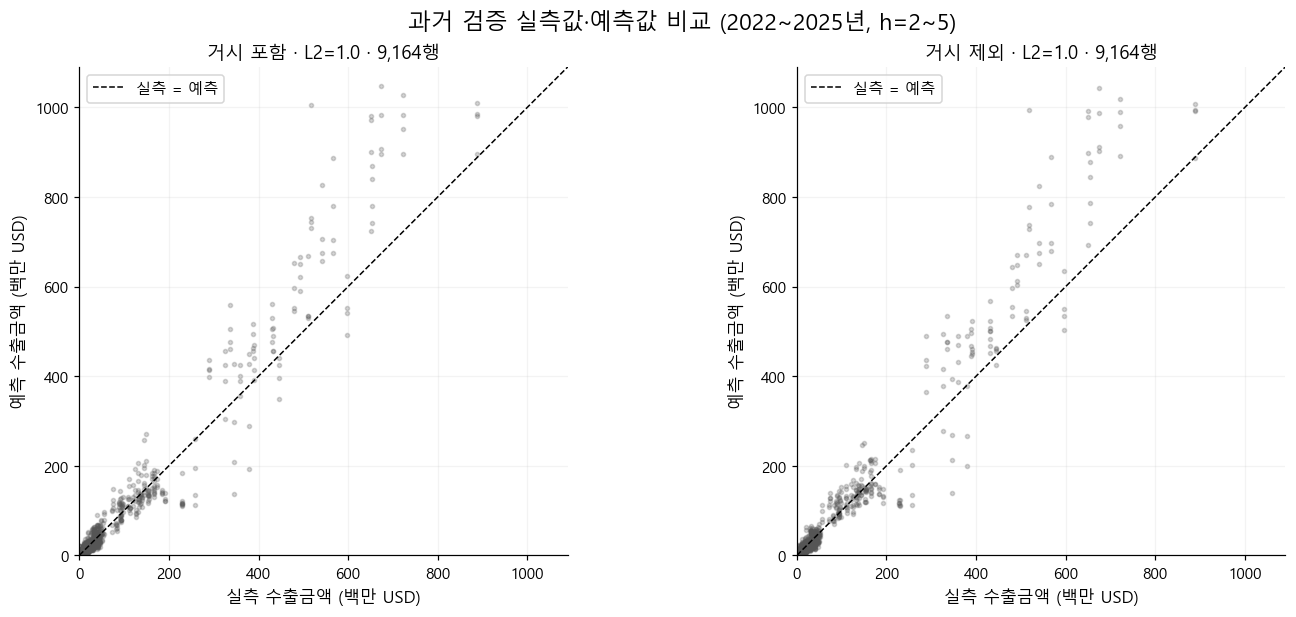

In [3]:
fig,axes=plt.subplots(1,2,figsize=(13,5.5),layout="constrained")
plot_rows=new[new.model_id.eq("lightgbm") & new.horizon_quarters.between(2,5)]
limit=float(plot_rows[[ACTUAL,PRED]].max().max())/1e6*1.04
for ax,(variant,label) in zip(axes,labels.items()):
    part=plot_rows[plot_rows.variant.eq(variant)]
    ax.scatter(part[ACTUAL]/1e6,part[PRED]/1e6,s=7,alpha=.25,c="#555555",rasterized=True)
    ax.plot([0,limit],[0,limit],"--",color="black",linewidth=1,label="실측 = 예측")
    ax.set(xlim=(0,limit),ylim=(0,limit),xlabel="실측 수출금액 (백만 USD)",ylabel="예측 수출금액 (백만 USD)",title=f"{label} · L2=1.0 · {len(part):,}행")
    ax.set_aspect("equal",adjustable="box")
    ax.grid(alpha=.15);ax.legend()
fig.suptitle("과거 검증 실측값·예측값 비교 (2022~2025년, h=2~5)",fontsize=15)
fig.savefig(FIGURES / "l2_actual_vs_predicted.png")
plt.show()


## 3. 립 제품 — 주요 4개국

HS 330410 · 예측 기준 2024Q3 · 국가별 세로축 범위 다름.

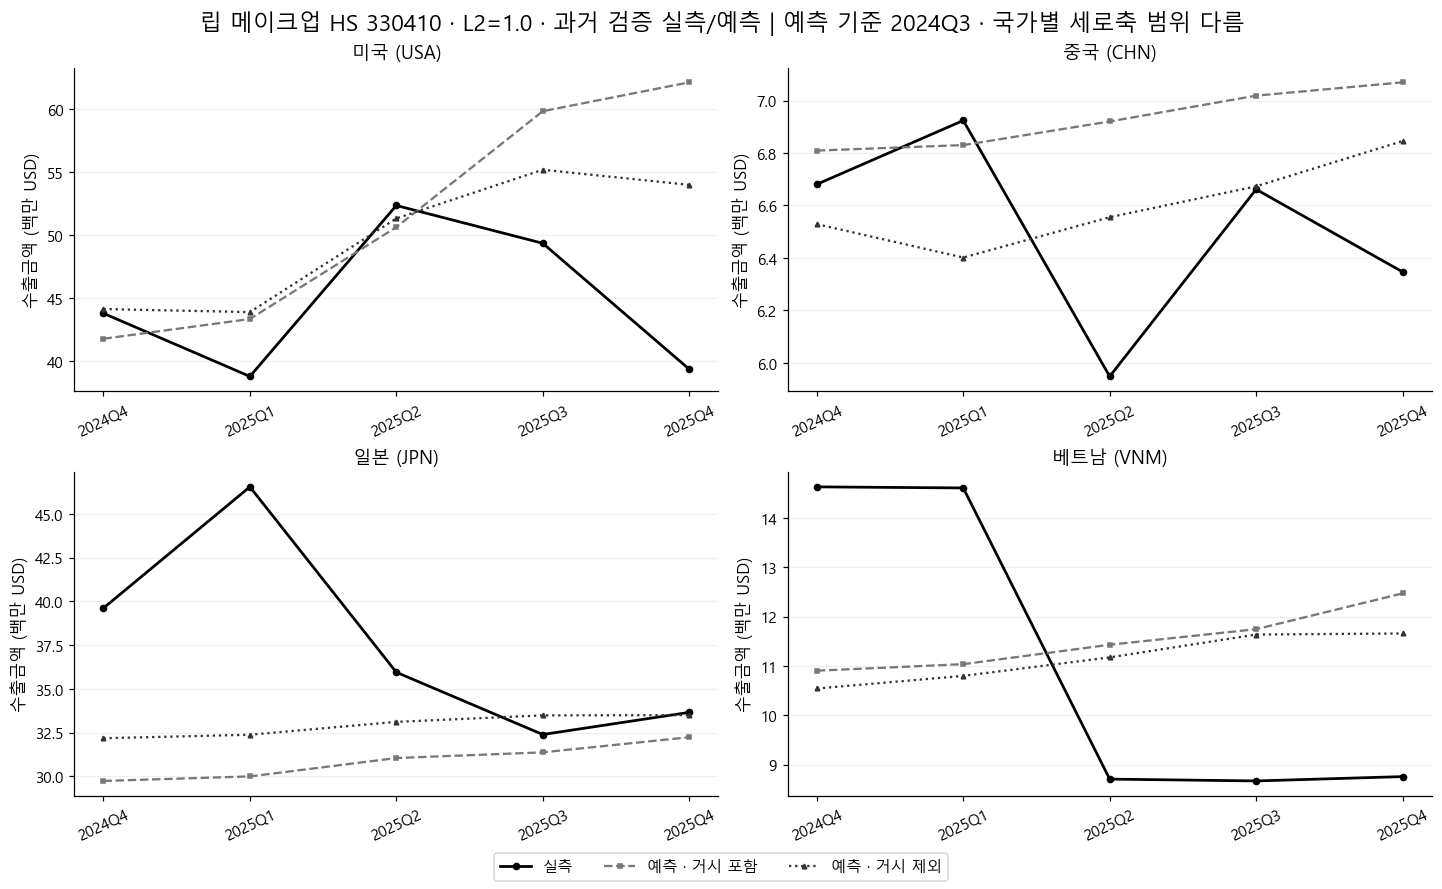

In [4]:
selected_hs = "330410"
selected_origin = "2024Q3"
example_countries = ["USA","CHN","JPN","VNM"]
targets = [str(x) for x in pd.period_range(pd.Period(selected_origin,freq="Q")+1,periods=5,freq="Q")]

def draw_country(ax,country):
    part=new[new.country_code.eq(country) & new.hs_code.eq(selected_hs) & new.origin_quarter.eq(selected_origin) & new.model_id.eq("lightgbm")]
    actual=part.drop_duplicates("target_quarter").set_index("target_quarter")[ACTUAL].reindex(targets)
    ax.plot(targets,actual.to_numpy(dtype=float)/1e6,"o-",color="black",label="실측",linewidth=1.8,markersize=4)
    for variant,style,color in [("with_macro","--","#777777"),("without_macro",":","#333333")]:
        pred=part[part.variant.eq(variant)].set_index("target_quarter")[PRED].reindex(targets)
        ax.plot(targets,pred.to_numpy(dtype=float)/1e6,marker="s" if variant=="with_macro" else "^",linestyle=style,color=color,label=f"예측 · {labels[variant]}",linewidth=1.5,markersize=3)
    ax.set_title(f"{country_names.get(country,country)} ({country})")
    ax.set_ylabel("수출금액 (백만 USD)")
    ax.tick_params(axis="x",labelrotation=25)
    ax.grid(axis="y",alpha=.2)
    if actual.notna().sum()==0:ax.text(.5,.5,"선택 기간에 평가 가능한 정답 없음",ha="center",transform=ax.transAxes)

fig,axes=plt.subplots(2,2,figsize=(13,8),layout="constrained")
for ax,country in zip(axes.flat,example_countries):draw_country(ax,country)
handles,legend_labels=axes.flat[0].get_legend_handles_labels()
fig.legend(handles,legend_labels,loc="outside lower center",ncol=3)
fig.suptitle(f"립 메이크업 HS {selected_hs} · L2=1.0 · 과거 검증 실측/예측 | 예측 기준 {selected_origin} · 국가별 세로축 범위 다름",fontsize=15)
fig.savefig(FIGURES / "l2_lip_four_countries.png")
plt.show()


## 4. 립 제품 — 20개국

미확보 값은 빈 구간으로 표시합니다. 국가별 세로축 범위는 다릅니다.

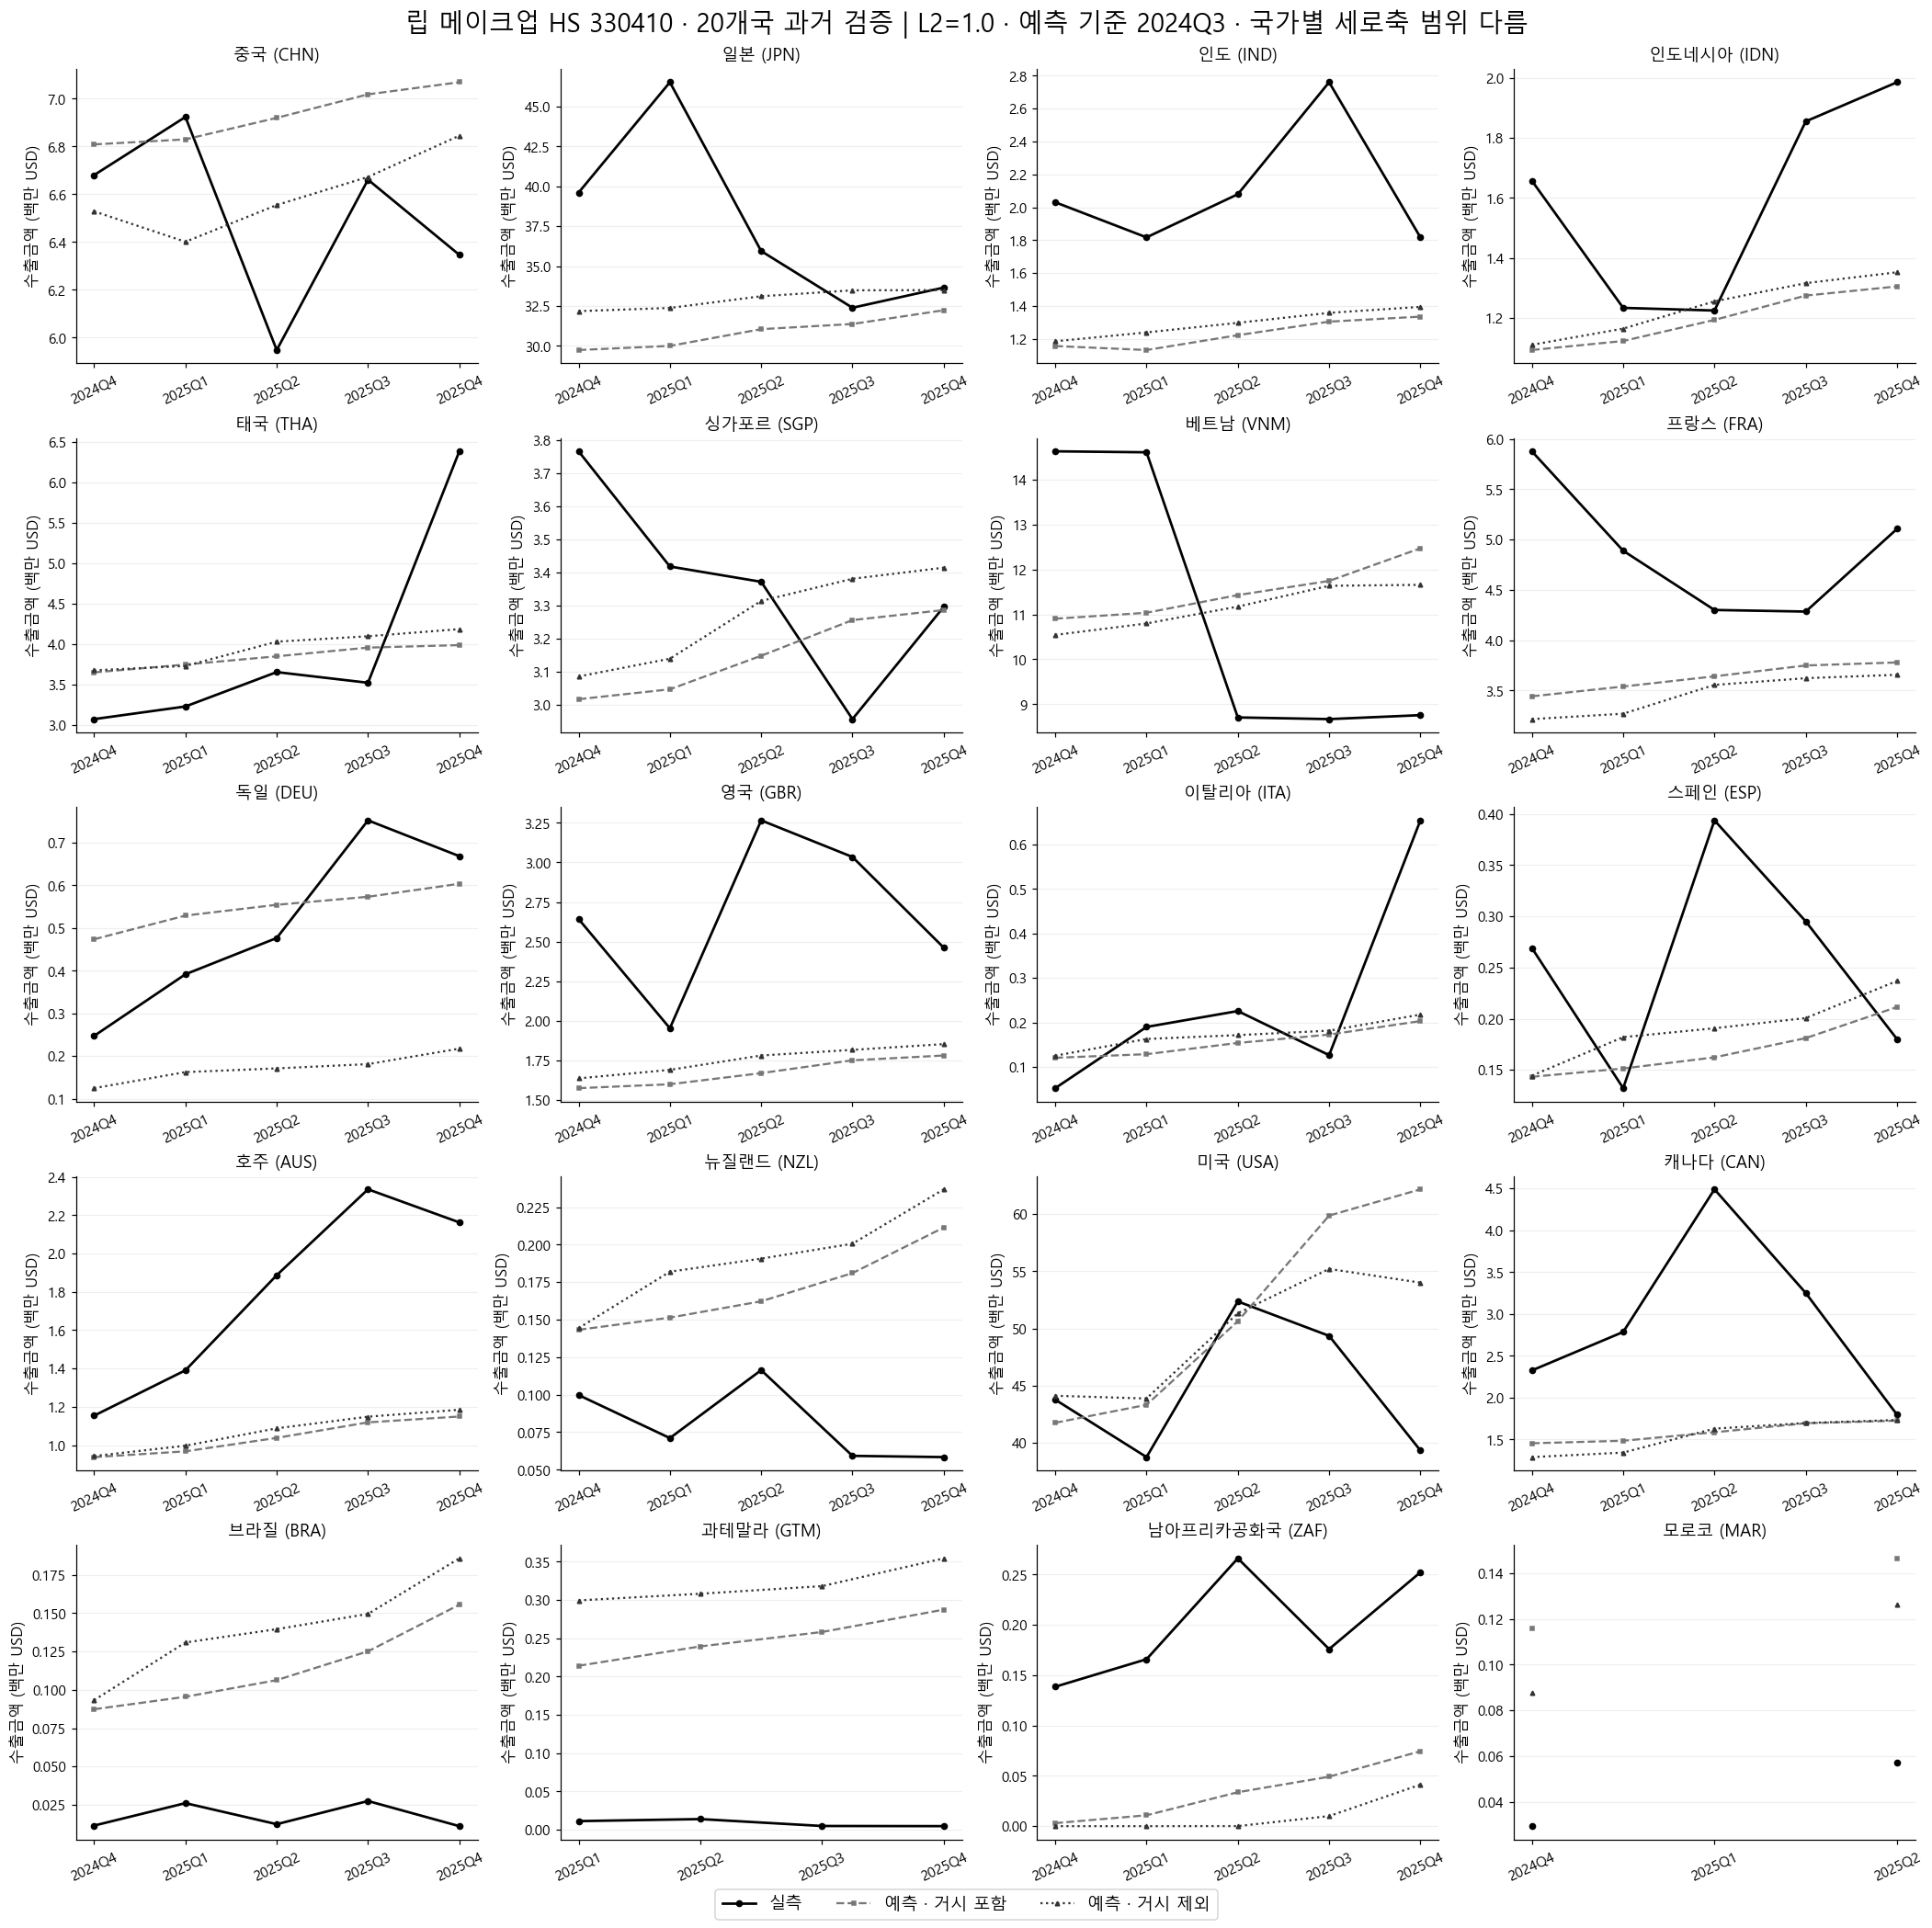

In [5]:
fig,axes=plt.subplots(5,4,figsize=(19,19),layout="constrained")
for ax,row in zip(axes.flat,countries):draw_country(ax,row["iso3"])
fig.legend(handles,legend_labels,loc="outside lower center",ncol=3,fontsize=12)
fig.suptitle(f"립 메이크업 HS {selected_hs} · 20개국 과거 검증 | L2=1.0 · 예측 기준 {selected_origin} · 국가별 세로축 범위 다름",fontsize=18)
fig.savefig(FIGURES / "l2_lip_all_20_countries.png")
plt.show()


## 5. 그래프 원본 값

단위: USD·FOB.

In [6]:
display(new.loc[new.hs_code.eq(selected_hs) & new.origin_quarter.eq(selected_origin) & new.model_id.eq("lightgbm"),
    ["country_code","hs_code","origin_quarter","target_quarter","horizon_quarters","variant",ACTUAL,PRED]].head(40))

,country_code,hs_code,origin_quarter,target_quarter,horizon_quarters,variant,target_export_value_usd,predicted_export_value_usd
18529,AUS,330410,2024Q3,2024Q4,1,with_macro,1154304.0,9.381071e+05
18530,AUS,330410,2024Q3,2025Q1,2,with_macro,1390757.0,9.681116e+05
18531,AUS,330410,2024Q3,2025Q2,3,with_macro,1886852.0,1.038255e+06
18532,AUS,330410,2024Q3,2025Q3,4,with_macro,2334689.0,1.119297e+06
18533,AUS,330410,2024Q3,2025Q4,5,with_macro,2162223.0,1.149695e+06
18565,BRA,330410,2024Q3,2024Q4,1,with_macro,11436.0,8.735449e+04
18566,BRA,330410,2024Q3,2025Q1,2,with_macro,26071.0,9.547013e+04
18567,BRA,330410,2024Q3,2025Q2,3,with_macro,12340.0,1.063525e+05
18568,BRA,330410,2024Q3,2025Q3,4,with_macro,27456.0,1.251474e+05
18569,BRA,330410,2024Q3,2025Q4,5,with_macro,11057.0,1.555459e+05
